# Preprocessing

## Data Loading and Setup

In [315]:
from pathlib import Path
import pandas as pd

# load data
DATA_PATH = '../data/repairs.csv'
df = pd.read_csv(DATA_PATH)

## Inspection

### General

In [316]:
print(df.shape)
print()
print(df.columns.tolist())
print()
df.head()

(178749, 11)

['repair_id', 'repair_date', 'repair_cafe_number', 'repair_cafe_name', 'country', 'kind_of_product', 'category', 'brand', 'estimated_year_of_production', 'repaired', 'repairability']



,repair_id,repair_date,repair_cafe_number,repair_cafe_name,country,kind_of_product,category,brand,estimated_year_of_production,repaired,repairability
0,0550_2026_0214_006,2026-02-14,550.0,Louth,GB,Vacuum cleaner,Household appliances electric,Henry,2005.0,no,3.0
1,0550_2026_0214_005,2026-02-14,550.0,Louth,GB,Accordion,Display and sound equipment,Microvox,1999.0,no,6.0
2,0250_2026_0307_018,2026-03-07,250.0,Madrid Medialab Matadero,ES,Television,Display and sound equipment,LG,2017.0,no,7.0
3,0882_2025_1122_018,2025-11-22,882.0,Berden,GB,Vacuum cleaner,Household appliances electric,Miele,2007.0,half,NaN
4,0250_2026_0307_017,2026-03-07,250.0,Madrid Medialab Matadero,ES,Table clock,Clocks / alarm clocks,Unknown/n.a.,NaN,yes,7.0


### Types

In preliminary experiments and manual data inspection, we found that some product types appeared only a handful of times, or even just once. These scarcd types are hard to learn from and introduce noise to the training data. Because of this, we inspect the type distribution below.

The counts are heavily right-skewed. Most distinct types are rare, while the majority of repairs sit in a very small set of very common types. For each cutoff we compute a score by finding the product of the share of types and the share of rows maintained. We select the cutoff with the highest score.


In [317]:
# kind_of_product is the product type
kind_counts = df['kind_of_product'].value_counts(dropna=False)
print(kind_counts)
print()
print((kind_counts / kind_counts.sum() * 100).round(2))

kind_of_product
Coffee maker           10770
Vacuum cleaner         10284
Trousers / pants        6769
Bicycle / Bike          4887
Sewing machine          4614
                       ...  
Juice jug                  1
Bong                       1
Rightholder back           1
Golf ball retriever        1
Listening aid              1
Name: count, Length: 1952, dtype: int64

kind_of_product
Coffee maker           6.03
Vacuum cleaner         5.75
Trousers / pants       3.79
Bicycle / Bike         2.73
Sewing machine         2.58
                       ... 
Juice jug              0.00
Bong                   0.00
Rightholder back       0.00
Golf ball retriever    0.00
Listening aid          0.00
Name: count, Length: 1952, dtype: float64


count     1952.0
mean        91.6
std        470.9
min          1.0
25%          2.0
50%          8.0
75%         35.2
max      10770.0
Name: count, dtype: float64

Cutoff      Share of kinds    Share of rows     Joint     
< 1         0.000             0.000             0.000     
< 5         0.378             0.008             0.374     
< 10        0.526             0.019             0.516     
< 20        0.665             0.040             0.639     
< 50        0.797             0.085             0.729     
< 100       0.876             0.145             0.749     
< 200       0.925             0.219             0.722     
< 500       0.963             0.352             0.624     
< 1000      0.983             0.504             0.488     
< 5000      0.998             0.844             0.155     
< 10000     0.999             0.882             0.118     

Best cutoff by joint score: < 100 (joint 0.749)


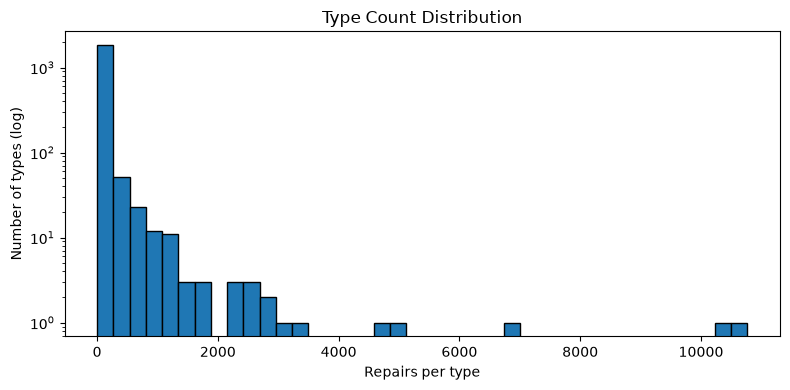

In [318]:
import matplotlib.pyplot as plt

print(kind_counts.describe().round(1))
print()

# trade-off for types below each cutoff
# joint = share of kinds removed * share of rows kept
cutoffs = [1, 5, 10, 20, 50, 100, 200, 500, 1000, 5000, 10000]
best_cutoff = None
best_joint = -1.0

print(f"{'Cutoff':<12}{'Share of kinds':<18}{'Share of rows':<18}{'Joint':<10}")
for cutoff in cutoffs:
    rare = kind_counts[kind_counts < cutoff]
    share_kinds = rare.size / kind_counts.size
    share_rows = rare.sum() / kind_counts.sum()
    joint = share_kinds * (1 - share_rows)

    if joint > best_joint:
        best_joint = joint
        best_cutoff = cutoff

    print(
        f"{'< ' + str(cutoff):<12}"
        f"{share_kinds:<18.3f}"
        f"{share_rows:<18.3f}"
        f"{joint:<10.3f}"
    )

MIN_KIND_COUNT = best_cutoff
print()
print(f"Best cutoff by joint score: < {MIN_KIND_COUNT} (joint {best_joint:.3f})")

plt.figure(figsize=(8, 4))
plt.hist(kind_counts, bins=40, edgecolor='black')
plt.yscale('log')
plt.title('Type Count Distribution')
plt.xlabel('Repairs per type')
plt.ylabel('Number of types (log)')
plt.tight_layout()
plt.show()


## Preprocessing

Shared cleaning on the full dataset. Types below `MIN_KIND_COUNT` are dropped. We keep both the full table and that reduced table so we can compare models later.

In [319]:
# remove rows where year of production is negative value or in the future, from repair date
repair_year = pd.to_datetime(df['repair_date'], errors='coerce').dt.year
df['estimated_year_of_production'] = pd.to_numeric(
    df['estimated_year_of_production'], errors='coerce'
)
invalid_year = (
    df['estimated_year_of_production'].lt(0)
    | df['estimated_year_of_production'].gt(repair_year)
)
df.loc[invalid_year, 'estimated_year_of_production'] = pd.NA

# drop rows with na col's
df = df.dropna(subset=[
    'estimated_year_of_production',
    'country',
    'category',
    'kind_of_product',
]).copy()

counts = df['kind_of_product'].value_counts()
kind_levels_reduced = counts[counts >= MIN_KIND_COUNT].index

# columns to keep
columns = [ 
    'country',
    'category',
    'kind_of_product',
    'estimated_year_of_production',
    'repaired',
    'repairability',
]

df = df[columns]

df_full = df.copy()
df_reduced = df.loc[df['kind_of_product'].isin(kind_levels_reduced)].copy()


print('MIN_KIND_COUNT:', MIN_KIND_COUNT)
print('Rows (full):', len(df_full), 'kinds:', df_full['kind_of_product'].nunique())
print('Rows (reduced):', len(df_reduced), 'kinds:', df_reduced['kind_of_product'].nunique())
df_reduced.head()

MIN_KIND_COUNT: 100
Rows (full): 64243 kinds: 1560
Rows (reduced): 48408 kinds: 117


,country,category,kind_of_product,estimated_year_of_production,repaired,repairability
0,GB,Household appliances electric,Vacuum cleaner,2005.0,no,3.0
2,ES,Display and sound equipment,Television,2017.0,no,7.0
3,GB,Household appliances electric,Vacuum cleaner,2007.0,half,NaN
7,ES,Display and sound equipment,Television,2010.0,no,7.0
8,ES,Display and sound equipment,Radio / tape recorder,1980.0,half,NaN


## Train and Test Split

In [320]:
from sklearn.model_selection import train_test_split

train_full, test_full = train_test_split(
    df_full, test_size=0.2, random_state=42
)
train_reduced, test_reduced = train_test_split(
    df_reduced, test_size=0.2, random_state=42
)

# Repaired Fitting

## Gradient Boosting

Model                       Macro F1    Trees   Test rows   
Majority (yes)              0.2482              9682        
With reduction              0.4369      100     9682        
Without reduction           0.4149      100     12849       


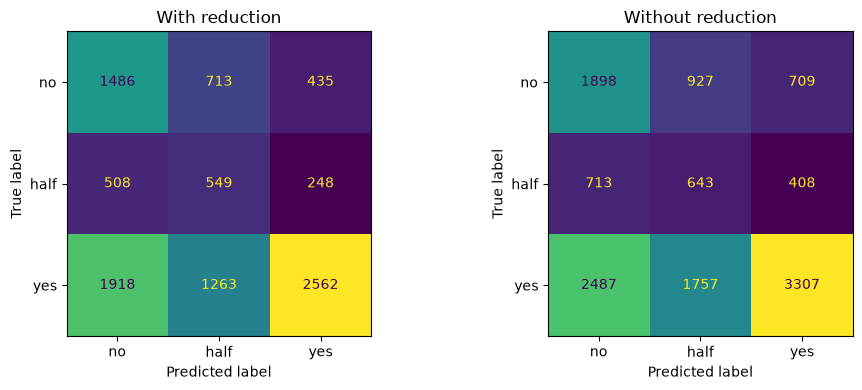

In [321]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.preprocessing import OrdinalEncoder
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import f1_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# drop repairability targets
# (to be used in later experiments)
train_full_ter, test_full_ter, train_reduced_ter, test_reduced_ter = [
    df.drop(columns='repairability')
    for df in (train_full, test_full, train_reduced, test_reduced)
]

LABELS = ('no', 'half', 'yes')

# categorical columns for encoding
categorical = ['country', 'category', 'kind_of_product']

splits = {
    'With reduction': (train_reduced_ter, test_reduced_ter),
    'Without reduction': (train_full_ter, test_full_ter),
}

# compute F1 of majority-only predictive model for baseline comparison
majority = train_reduced_ter['repaired'].mode().iloc[0]
baseline = [majority] * len(test_reduced)
print(f"{'Model':<28}{'Macro F1':<12}{'Trees':<8}{'Test rows':<12}")
print(
    f"{'Majority (' + majority + ')':<28}"
    f"{f1_score(test_reduced_ter['repaired'], baseline, average='macro', labels=list(LABELS)):<12.4f}"
    f"{'':<8}"
    f"{len(test_reduced):<12}"
)

preds = {}
for label, (train_df, test_df) in splits.items():
    X_train = train_df.drop(columns='repaired')
    X_test = test_df.drop(columns='repaired')

    y_train = train_df['repaired']
    y_test = test_df['repaired']

    encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
    X_train[categorical] = encoder.fit_transform(X_train[categorical])
    X_test[categorical] = encoder.transform(X_test[categorical])

    model = GradientBoostingClassifier(random_state=42)
    model.fit(
        X_train,
        y_train,
        sample_weight=compute_sample_weight('balanced', train_df['repaired']),
    )
    pred = model.predict(X_test)
    preds[label] = (y_test, pred)

    print(
        f"{label:<28}"
        f"{f1_score(y_test, pred, average='macro', labels=list(LABELS)):<12.4f}"
        f"{model.n_estimators_:<8}"
        f"{len(test_df):<12}"
    )

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (label, (y_test, pred)) in zip(axes, preds.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, labels=list(LABELS), ax=ax, colorbar=False
    )
    ax.set_title(label)
plt.tight_layout()
plt.show()


# Repairability Training

## Gradient Boosting

In [322]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import mean_absolute_error
import pandas as pd

# Filter valid repairability scores (1-10), drop 'repaired' target, and cast to int
train_full_score, test_full_score, train_reduced_score, test_reduced_score = [
    df[pd.to_numeric(df['repairability'], errors='coerce').between(1, 10)].drop(columns='repaired').astype({'repairability': int})
    for df in (train_full, test_full, train_reduced, test_reduced)
]

# categorical columns for encoding
categorical = ['country', 'category', 'kind_of_product']

splits = {
    'With reduction': (train_reduced_score, test_reduced_score),
    'Without reduction': (train_full_score, test_full_score),
}

# compute MAE of median-only predictive model for baseline comparison
median_val = train_reduced_score['repairability'].median()
baseline = [median_val] * len(test_reduced_score)
baseline_rounded = int(round(median_val))
y_test_baseline = test_reduced_score['repairability'].to_numpy()

print(f"{'Model':<28}{'MAE':<12}{'Exact':<12}{'Within 1':<12}{'Trees':<8}{'Test rows':<12}")
print(
    f"{'Median (' + str(baseline_rounded) + ')':<28}"
    f"{mean_absolute_error(y_test_baseline, baseline):<12.4f}"
    f"{(y_test_baseline == baseline_rounded).mean():<12.4f}"
    f"{(abs(y_test_baseline - baseline_rounded) <= 1).mean():<12.4f}"
    f"{'':<8}"
    f"{len(test_reduced_score):<12}"
)

for label, (train_df, test_df) in splits.items():
    X_train = train_df.drop(columns='repairability')
    X_test = test_df.drop(columns='repairability')

    y_train = train_df['repairability']
    y_test = test_df['repairability']
    y_test_arr = y_test.to_numpy()

    encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
    X_train[categorical] = encoder.fit_transform(X_train[categorical])
    X_test[categorical] = encoder.transform(X_test[categorical])

    model = GradientBoostingRegressor(random_state=42)
    model.fit(X_train, y_train)
    
    pred = model.predict(X_test)
    rounded = pd.Series(pred).clip(1, 10).round().astype(int).to_numpy()

    print(
        f"{label:<28}"
        f"{mean_absolute_error(y_test, pred):<12.4f}"
        f"{(rounded == y_test_arr).mean():<12.4f}"
        f"{(abs(rounded - y_test_arr) <= 1).mean():<12.4f}"
        f"{model.n_estimators_:<8}"
        f"{len(test_df):<12}"
    )

Model                       MAE         Exact       Within 1    Trees   Test rows   
Median (7)                  2.2456      0.1249      0.3887              8346        
With reduction              2.2325      0.1116      0.3753      100     8346        
Without reduction           2.2767      0.1074      0.3620      100     11020       
